# Chapter 00: The Physics of Belief — Python Laboratory
### *Simulating the 20 Questions Game, Surprisal Functions, and the Illusion of Green Retries*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/00_the_physics_of_belief.ipynb) | [Next: Ch 01: Quantifying Uncertainty (Python)](01_quantifying_uncertainty_entropy_and_bayes.ipynb)**

---

## 1. Overview & Setup

In this laboratory, we write executable Python code to verify the foundations introduced in Chapter 00:
1. **The 20 Questions Game**: Simulating binary bisection search to verify that finding $1$ item out of $N$ takes exactly $\lceil \log_2 N \rceil$ questions.
2. **The Surprisal Function**: Implementing Claude Shannon's self-information metric $I(x) = -\log_2 P(x)$ and comparing rare anomalies against routine events.
3. **The Flaky Retry Simulator**: Simulating a CI/CD test runner to visualize how hitting "re-run" systematically masks flaky test failures and tricks engineers.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. Simulation 1: The 20 Questions Game & State Space Counting

Let us write a function that performs binary search to find an arbitrary secret integer in range $[1, N]$ and counts the exact number of queries required.


In [2]:
def simulate_20_questions(N, secret=None):
    if secret is None:
        secret = np.random.randint(1, N + 1)
    
    low = 1
    high = N
    queries = 0
    
    while low < high:
        queries += 1
        mid = (low + high) // 2
        # Question: Is secret <= mid?
        if secret <= mid:
            high = mid
        else:
            low = mid + 1
            
    return queries, low == secret

# Test across powers of 2:
sizes = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 1048576]
print("=" * 60)
print(f"{'State Space Size N':<22} | {'Log2(N)':<10} | {'Queries Required':<18}")
print("=" * 60)
for N in sizes:
    q, verified = simulate_20_questions(N)
    theoretical = int(np.ceil(np.log2(N)))
    print(f"{N:<22} | {theoretical:<10} | {q:<18} (Match: {q == theoretical})")
print("=" * 60)


State Space Size N     | Log2(N)    | Queries Required  


2                      | 1          | 1                  (Match: True)
4                      | 2          | 2                  (Match: True)
8                      | 3          | 3                  (Match: True)
16                     | 4          | 4                  (Match: True)
32                     | 5          | 5                  (Match: True)
64                     | 6          | 6                  (Match: True)
128                    | 7          | 7                  (Match: True)
256                    | 8          | 8                  (Match: True)
512                    | 9          | 9                  (Match: True)
1024                   | 10         | 10                 (Match: True)
1048576                | 20         | 20                 (Match: True)


---

## 3. Simulation 2: Shannon Surprisal — The Asymmetry of Information

We compute the Shannon self-information $I(x) = -\log_2 P(x)$ across a spectrum of event probabilities, from certainty ($P=1.0$) to a one-in-a-million black swan ($P=10^{-6}$).


In [3]:
def surprisal(p):
    # Computes Shannon surprisal in bits for event with probability p.
    p = np.asarray(p, dtype=np.float64)
    return -np.log2(p)

probs = np.array([1.0, 0.999, 0.90, 0.50, 0.10, 0.01, 0.001, 1e-4, 1e-6])
bits = surprisal(probs)

print("=" * 70)
print(f"{'Event Probability P':<22} | {'Surprise (Bits)':<18} | {'Physical Interpretation'}")
print("=" * 70)
for p, b in zip(probs, bits):
    if p == 1.0:
        desc = "Certain event (Zero new knowledge)"
    elif p >= 0.90:
        desc = "Routine pass in CI (Boring, minimal info)"
    elif p == 0.50:
        desc = "Fair coin flip (Exactly 1 bit)"
    elif p >= 0.01:
        desc = "Occasional flake (Noticeable surprise)"
    else:
        desc = "Critical black swan failure (Massive surprise payload!)"
    print(f"{p:<22.6f} | {b:<18.4f} | {desc}")
print("=" * 70)


Event Probability P    | Surprise (Bits)    | Physical Interpretation
1.000000               | -0.0000            | Certain event (Zero new knowledge)
0.999000               | 0.0014             | Routine pass in CI (Boring, minimal info)
0.900000               | 0.1520             | Routine pass in CI (Boring, minimal info)
0.500000               | 1.0000             | Fair coin flip (Exactly 1 bit)
0.100000               | 3.3219             | Occasional flake (Noticeable surprise)
0.010000               | 6.6439             | Occasional flake (Noticeable surprise)
0.001000               | 9.9658             | Critical black swan failure (Massive surprise payload!)
0.000100               | 13.2877            | Critical black swan failure (Massive surprise payload!)
0.000001               | 19.9316            | Critical black swan failure (Massive surprise payload!)


---

## 4. Simulation 3: The Illusion of the Green Retry

Now we simulate the cognitive trap of CI retry buttons.
Suppose a flaky test has an inherent failure rate $\theta \in [0.01, 0.50]$.
If an engineering team allows up to $K$ retries upon failure:
* What is the probability that the test eventually passes by luck?
* How many flaky defects escape undetected into production?


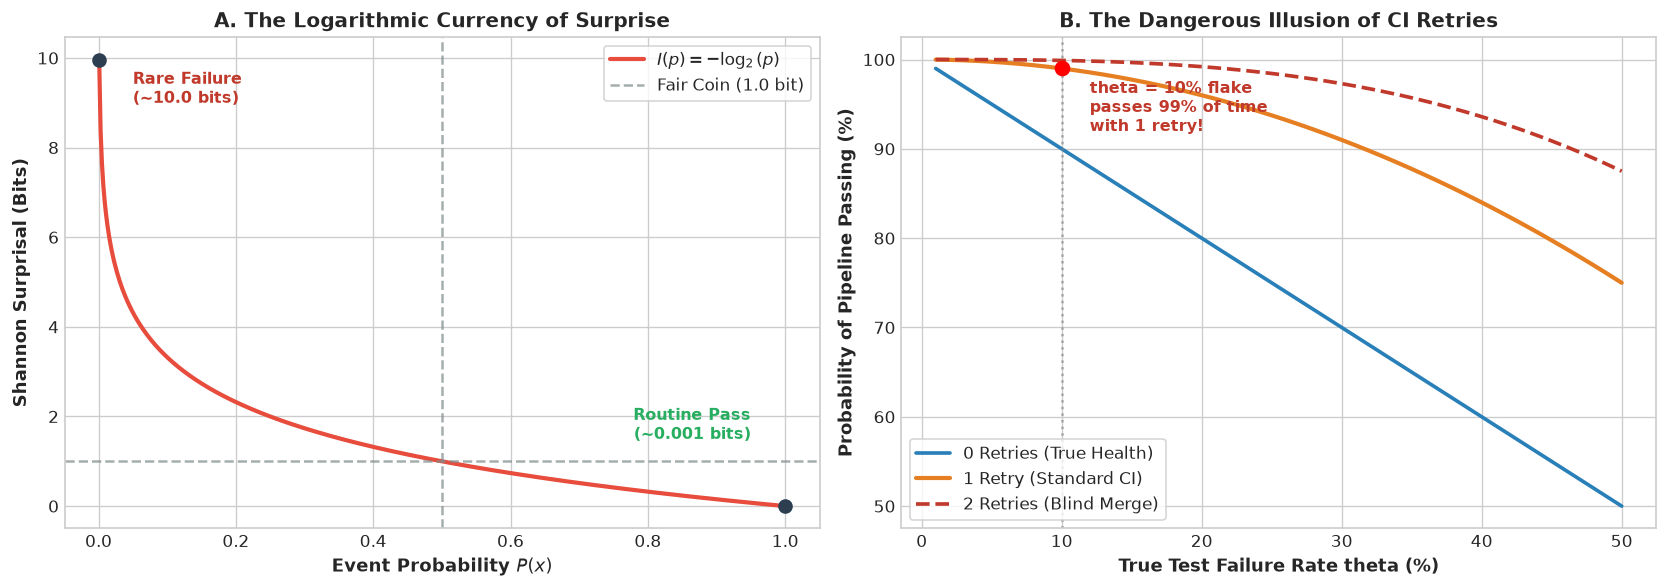

In [4]:
def simulate_retry_policy(theta, max_retries=1, num_trials=10000):
    # Trial is successful if at least ONE run in (1 + max_retries) attempts passes
    # Probability that all (1 + max_retries) attempts FAIL is theta^(1 + max_retries)
    # Therefore, probability of false pass is 1 - theta^(1 + max_retries)
    total_runs = 1 + max_retries
    simulated_runs = np.random.uniform(0, 1, size=(num_trials, total_runs))
    failures = (simulated_runs < theta)
    all_failed = np.all(failures, axis=1)
    pass_rate = 1.0 - np.mean(all_failed)
    return pass_rate

thetas = np.linspace(0.01, 0.50, 50)
pass_0_retries = 1.0 - thetas
pass_1_retry = 1.0 - (thetas ** 2)
pass_2_retries = 1.0 - (thetas ** 3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Surprisal Curve
p_curve = np.linspace(0.001, 1.0, 500)
axes[0].plot(p_curve, -np.log2(p_curve), color='#e74c3c', lw=2.5, label=r'$I(p) = -\log_2(p)$')
axes[0].axvline(0.5, color='#7f8c8d', ls='--', alpha=0.7, label='Fair Coin (1.0 bit)')
axes[0].axhline(1.0, color='#7f8c8d', ls='--', alpha=0.7)
axes[0].scatter([0.999, 0.001], [-np.log2(0.999), -np.log2(0.001)], color='#2c3e50', zorder=5, s=60)
axes[0].text(0.95, 1.5, "Routine Pass\n(~0.001 bits)", ha='right', fontsize=9.5, fontweight='bold', color='#27ae60')
axes[0].text(0.05, 9.0, "Rare Failure\n(~10.0 bits)", ha='left', fontsize=9.5, fontweight='bold', color='#c0392b')
axes[0].set_xlabel("Event Probability $P(x)$", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Shannon Surprisal (Bits)", fontsize=11, fontweight='bold')
axes[0].set_title("A. The Logarithmic Currency of Surprise", fontsize=12, fontweight='bold')
axes[0].legend(frameon=True)

# Panel 2: The Retry Illusion
axes[1].plot(thetas * 100, pass_0_retries * 100, color='#2980b9', lw=2.2, label='0 Retries (True Health)')
axes[1].plot(thetas * 100, pass_1_retry * 100, color='#e67e22', lw=2.5, label='1 Retry (Standard CI)')
axes[1].plot(thetas * 100, pass_2_retries * 100, color='#c0392b', lw=2.2, ls='--', label='2 Retries (Blind Merge)')
axes[1].axvline(10, color='gray', ls=':', alpha=0.6)
axes[1].scatter([10], [99.0], color='red', s=70, zorder=5)
axes[1].text(12, 92, "theta = 10% flake\npasses 99% of time\nwith 1 retry!", fontsize=9.5, fontweight='bold', color='#c0392b')
axes[1].set_xlabel("True Test Failure Rate theta (%)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Probability of Pipeline Passing (%)", fontsize=11, fontweight='bold')
axes[1].set_title("B. The Dangerous Illusion of CI Retries", fontsize=12, fontweight='bold')
axes[1].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()


---

## 5. 3-Tier Exercises & Explorations

### Tier 1: Warmup — Bit Counting
Calculate the Shannon surprisal in bits for:
1. A fair 6-sided die rolling a $6$.
2. A fair 20-sided D&D die rolling a natural $20$.
3. An automated end-to-end payment test that fails once every $250$ executions.

### Tier 2: Intermediate — The Cumulative Surprise of Independent Runs
Write a function `cumulative_surprise(results, theta)` where `results` is a list of booleans (`True` for Pass, `False` for Fail) and `theta` is the assumed flakiness probability.
Verify numerically that the total surprise of $10$ independent runs equals the sum of the individual surprises:
$$I(R_1, R_2, \dots, R_{10}) = \sum_{i=1}^{10} I(R_i)$$

### Tier 3: Advanced Research — The Optimal Retry Budget
If each test run costs $\$0.05$ in cloud compute and an undetected production outage costs $\$5,000$ in lost revenue, write an optimization script that plots total expected cost as a function of the retry threshold. At what failure rate $\theta$ does re-running a test cost more than quarantine?


In [5]:
# Solution verification for Tier 1:
p_die6 = 1.0 / 6.0
p_die20 = 1.0 / 20.0
p_payment = 1.0 / 250.0

print("Tier 1 Solutions:")
print(f"1. 6-sided die (roll 6):           {surprisal(p_die6):.4f} bits")
print(f"2. 20-sided die (roll 20):         {surprisal(p_die20):.4f} bits")
print(f"3. Payment test (1 in 250 fail):   {surprisal(p_payment):.4f} bits")


Tier 1 Solutions:
1. 6-sided die (roll 6):           2.5850 bits
2. 20-sided die (roll 20):         4.3219 bits
3. Payment test (1 in 250 fail):   7.9658 bits


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/00_the_physics_of_belief.ipynb) | [Next: Ch 01: Quantifying Uncertainty (Python)](01_quantifying_uncertainty_entropy_and_bayes.ipynb)**
